# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [1]:
# Twoje rozwiązanie
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)
    train_df = imdb["train"].to_pandas()
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)
def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)
train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])
class_share = train_df["label"].value_counts(normalize=True)
median_words = train_df["text"].str.split().str.len().median()
print("Kształt zbiorów:", train_df.shape, test_df.shape)
print("Udział klas (train):", class_share.round(3).to_dict())
print(f"Mediana liczby słów w recenzji: {median_words:.0f}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Kształt zbiorów: (25000, 2) (25000, 2)
Udział klas (train): {0: 0.5, 1: 0.5}
Mediana liczby słów w recenzji: 173


In [2]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [3]:
# Twoje rozwiązanie
X_train, y_train = train_df["text"], train_df["label"]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000),
}
wiersze = []
for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), X_train, y_train, cv=cv)
    wiersze.append({
        "model": nazwa,
        "CV": r["test_score"].mean(),
        "CV odch.": r["test_score"].std(),
        "czas uczenia [s]": r["fit_time"].mean(),
    })
porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)

,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.862,0.002,5.175
liniowy SVM,0.893,0.001,3.823
regresja logistyczna,0.885,0.002,6.378


In [4]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

Na pełnym zbiorze wszystkie modele osiągnęły wyraźnie wyższą skuteczność niż we wzorze z 5000 recenzji: naiwny Bayes poprawił wynik z 0.820 do 0.862, liniowy SVM z 0.862 do 0.893, a regresja logistyczna z 0.841 do 0.885. Zwiększenie zbioru treningowego 5x podniosło dokładność modeli o około 3 do 4.4 pp oraz zmniejszyło odchylenie standardowe między rundami walidacji krzyżowej (z ok 0.010 do 0.001-0.002), ponieważ rzadziej występujące słowa pojawiają się w większym zbiorze wystarczająco często, by lepiej oszacować ich wagi. Kolejność modeli pod względem jakości nie zmieniła się: liniowy SVM, regresja logistyczna, naiwny Bayes.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [5]:
# Twoje rozwiązanie
pipe_svm = make_pipeline(TfidfVectorizer(min_df=2), LinearSVC())
param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1],
}
gs = GridSearchCV(pipe_svm, param_grid, cv=cv)
gs.fit(X_train, y_train)
print("Najlepsze parametry:", gs.best_params_)
print(f"Najlepszy wynik CV: {gs.best_score_:.4f}")
pd.DataFrame(gs.cv_results_)[[
    "param_tfidfvectorizer__ngram_range",
    "param_linearsvc__C",
    "mean_test_score",
    "mean_fit_time",
]].round(3)

Najlepsze parametry: {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
Najlepszy wynik CV: 0.9065


,param_tfidfvectorizer__ngram_range,param_linearsvc__C,mean_test_score,mean_fit_time
0,"(1, 1)",0.1,0.888,3.868
1,"(1, 2)",0.1,0.889,10.563
2,"(1, 1)",1.0,0.892,3.887
3,"(1, 2)",1.0,0.906,10.289


In [6]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

Na pełnym zbiorze jest inaczej niż we wzorze - dodanie bigramów wyraźnie poprawia wynik (dla C=1.0 średnia dokładność w walidacji krzyżowej rośnie z 0.892 do 0.906). Większy zbiór pomaga właśnie bigramom, ponieważ możliwych par słów jest wielokrotnie więcej niż pojedynczych słów i na małym zbiorze większość sensownych par pojawia się zbyt rzadko, by model mógł wiarygodnie wyznaczyć ich wagi, natomiast na 25 000 recenzjach istotne wyrażenia dwuwyrazowe (takie jak negacje czy stopniowanie) powtarzają się już wystarczająco często. Model z bigramami uczy się ok 3 razy wolniej (czas uczenia rośnie z ok 4 s do ponad 10 s), ponieważ wektoryzator musi wyznaczyć i zliczyć wszystkie pary sąsiednich słów, przez co słownik i liczba kolumn macierzy rosną kilkukrotnie, a każda recenzja ma około dwa razy więcej niezerowych cech.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy (test): 0.903


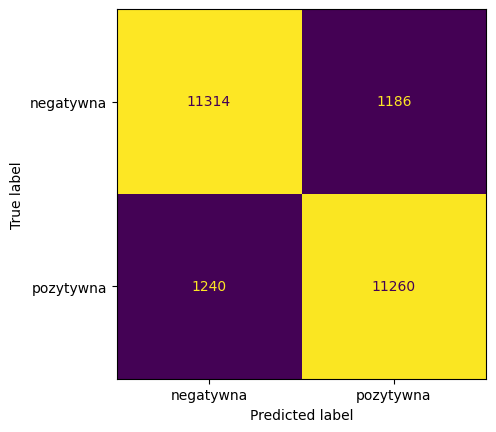

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [7]:
# Twoje rozwiązanie
X_test, y_test = test_df["text"], test_df["label"]
model_koncowy = gs.best_estimator_
y_pred = model_koncowy.predict(X_test)
acc_test = model_koncowy.score(X_test, y_test)
print(f"accuracy (test): {acc_test:.3f}")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["negatywna", "pozytywna"], colorbar=False
)
plt.show()
print(classification_report(y_test, y_pred, target_names=["negatywna", "pozytywna"], digits=3))

In [8]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

15 cech o najmniejszej wadze:
worst            -4.187
awful            -3.718
bad              -3.640
boring           -3.461
poor             -3.270
the worst        -3.183
waste            -2.919
disappointment   -2.605
terrible         -2.583
worse            -2.567
poorly           -2.511
disappointing    -2.463
dull             -2.420
unfortunately    -2.396
annoying         -2.333
dtype: float64

15 cech o największej wadze:
best         1.835
favorite     1.854
bit          1.856
loved        1.876
superb       1.906
brilliant    1.945
the best     1.955
enjoyable    1.965
today        2.204
amazing      2.208
fun          2.286
wonderful    2.566
perfect      2.752
excellent    3.237
great        3.571
dtype: float64


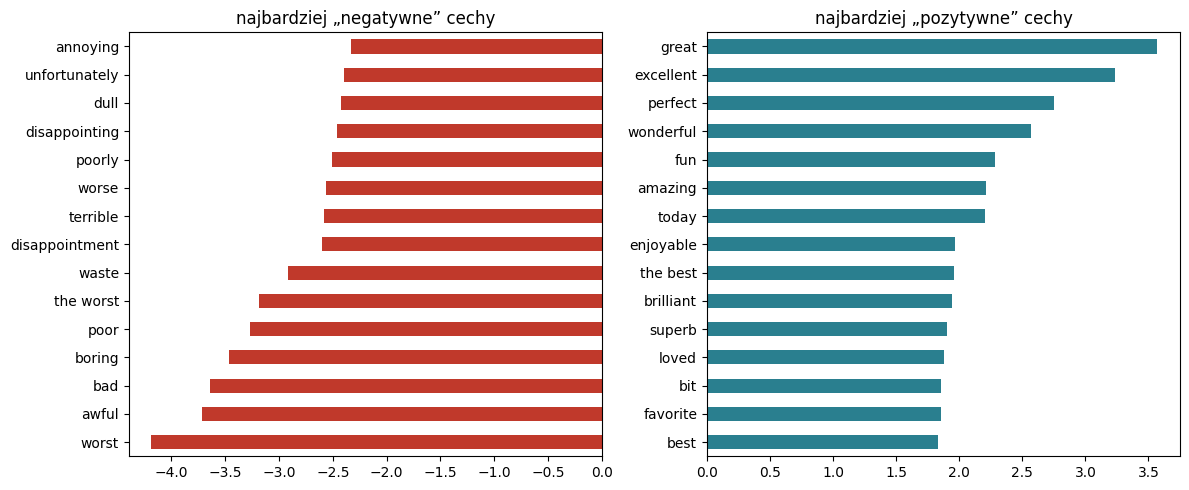


Liczba błędów: 2426 / 25000

Przykład błędu 1 (prawdziwa: 0, predykcja: 1)
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other action guys (Segal and Dolph) have thought about putting out the past few years. Van Damme is good in the movie, the movie is only worth watching to Van Damme fans. It is not as good as Wake of Death (whi

Przykład błędu 2 (prawdziwa: 0, predykcja: 1)
Ben, (Rupert Grint), is a deeply unhappy adolescent, the son of his unhappily married parents. His father, (Nicholas Farrell), is a vicar and his mother, (Laura Linney), is ... well, let's just say she's a somewhat hypocritical soldier in Jesus' army. It's only when he takes a summer job as an assistant to a foul-mouthed, eccentric, once-famous and now-forgotten actress Evi

In [9]:
# Twoje rozwiązanie
slowa = model_koncowy[0].get_feature_names_out()
wagi = pd.Series(model_koncowy[-1].coef_[0], index=slowa).sort_values()
print("15 cech o najmniejszej wadze:")
print(wagi.head(15).round(3))
print("\n15 cech o największej wadze:")
print(wagi.tail(15).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
wagi.head(15).plot.barh(ax=axes[0], color="#c0392b", title="najbardziej „negatywne” cechy")
wagi.tail(15).plot.barh(ax=axes[1], color="#2a7f8f", title="najbardziej „pozytywne” cechy")
fig.tight_layout()
plt.show()

bledy = test_df.assign(pred=y_pred)[y_pred != y_test.values]
print(f"\nLiczba błędów: {len(bledy)} / {len(test_df)}")
for idx, (_, row) in enumerate(bledy.head(3).iterrows(), 1):
    print(f"\nPrzykład błędu {idx} (prawdziwa: {row['label']}, predykcja: {row['pred']})")
    print(row["text"][:500])
moje_recenzje = [
    "An absolute masterpiece with breathtaking cinematography and unforgettable performances.",
    "A complete disaster, terrible script and the worst acting I have seen in years.",
    "I thought it would be boring, but this movie was not bad at all and actually quite enjoyable.",
    "The plot was not good and the characters were not interesting for a single moment.",
    "What a brilliant idea to spend two hours watching a masterpiece of pure boredom and wasted talent.",
]
print("\nPredykcje dla własnych recenzji")
moje_pred = model_koncowy.predict(moje_recenzje)
moje_wyniki = model_koncowy.decision_function(moje_recenzje)
for tekst, pred, wynik in zip(moje_recenzje, moje_pred, moje_wyniki):
    etykieta = "pozytywna (1)" if pred == 1 else "negatywna (0)"
    print(f"{etykieta:14s} [wynik SVM = {wynik:+.2f}]  {tekst}")

In [10]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

1 Wśród 15 najważniejszych cech znalazły się bigramy the worst oraz the best. Pokazuje to, że model nauczył się wychwytywać całe dwuwyrazowe konstrukcje oceniające i odróżniać je od pojedynczych słów, które mogą występować w innym kontekście.

2 Wszystkie trzy przykłady to recenzje negatywne sklasyfikowane przez model jako pozytywne. W pierwszym błędzie recenzent wielokrotnie używa pozytywnych słów, a krytykuje film bardzo łagodnie jako propozycję tylko dla fanów Van Damme. W drugim błędzie początkowy fragment to sam opis fabuły i postaci bez bezpośredniej krytyki filmu. W trzecim błędzie autor pisze, że lubi ten gatunek i film był całkiem przyjemny, choć narzeka na grę aktorską i dziwne sceny. We wszystkich tych przypadkach człowiek po przeczytaniu samego fragmentu również miałby wątpliwości co do końcowej oceny.

3 Model źle ocenił trzecią recenzję, uznając ją za negatywną mimo pozytywnego wydźwięku, a w piątej, ironicznej recenzji wynik był bliski progu decyzyjnego (-0.45). Wspólną cechą tych zdań jest kontrast z oczekiwaniami, negacja słów negatywnych (not bad at all) oraz ironia, przez co pojedyncze słowa o silnych wagach (np boring, bad, brilliant, masterpiece) mają w całym zdaniu znaczenie odwrotne niż ich dosłowna waga.

4 Granica podejścia worek słów + model liniowy leży w tym, że model jedynie sumuje wagi pojedynczych słów i krótkich n-gramów, nie rozumiejąc składni całego zdania, relacji między odległymi częściami wypowiedzi ani ironii. Aby poradzić sobie z takimi przykładami, model musiałby uwzględniać pełny kontekst zdania i zależności dalekiego zasięgu, co potrafią modele oparte na embeddingach kontekstowych i architekturze Transformer.